<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp03_Decision_Tree_ID3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 3: Decision Tree - ID3 Algorithm
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Demonstrate the working of the decision-tree based ID3 algorithm. Use an appropriate data set for building the decision tree and apply this knowledge to classify a new sample.

## Background
ID3 builds a tree top-down. At each node it picks the attribute with the highest **information gain**:

`Entropy(S) = - sum p_i * log2(p_i)`  and  `Gain(S, A) = Entropy(S) - sum (|S_v|/|S|) * Entropy(S_v)`

Growth stops when all examples at a node share one class or no attributes remain.


## Setup: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
The **PlayTennis** dataset (14 days of weather and whether tennis was played) is the standard textbook example for ID3. We save it as a CSV.

In [2]:
rows = [
 ["Sunny","Hot","High","Weak","No"],       ["Sunny","Hot","High","Strong","No"],
 ["Overcast","Hot","High","Weak","Yes"],   ["Rain","Mild","High","Weak","Yes"],
 ["Rain","Cool","Normal","Weak","Yes"],    ["Rain","Cool","Normal","Strong","No"],
 ["Overcast","Cool","Normal","Strong","Yes"], ["Sunny","Mild","High","Weak","No"],
 ["Sunny","Cool","Normal","Weak","Yes"],   ["Rain","Mild","Normal","Weak","Yes"],
 ["Sunny","Mild","Normal","Strong","Yes"], ["Overcast","Mild","High","Strong","Yes"],
 ["Overcast","Hot","Normal","Weak","Yes"], ["Rain","Mild","High","Strong","No"],
]
cols = ["Outlook", "Temperature", "Humidity", "Wind", "PlayTennis"]
pd.DataFrame(rows, columns=cols).to_csv("playtennis.csv", index=False)
print("Saved playtennis.csv")

Saved playtennis.csv


## Step 2: Data Loading
Load the CSV file.

In [3]:
df = pd.read_csv("playtennis.csv")
df

,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


## Step 3: Data Preprocessing
ID3 works directly on categorical attributes, so no encoding is needed for our own implementation. We still check for missing values and whitespace.

In [4]:
df = df.apply(lambda c: c.str.strip())
print("Missing values:", df.isnull().sum().sum())
target = "PlayTennis"
features = [c for c in df.columns if c != target]
print("Features:", features)

Missing values: 0
Features: ['Outlook', 'Temperature', 'Humidity', 'Wind']


## Step 4: Exploratory Data Analysis (EDA)
Look at the class balance and how each attribute splits the classes.

            count unique    top freq
Outlook        14      3  Sunny    5
Temperature    14      3   Mild    6
Humidity       14      2   High    7
Wind           14      2   Weak    8
PlayTennis     14      2    Yes    9

Class distribution:
 PlayTennis
Yes    9
No     5
Name: count, dtype: int64


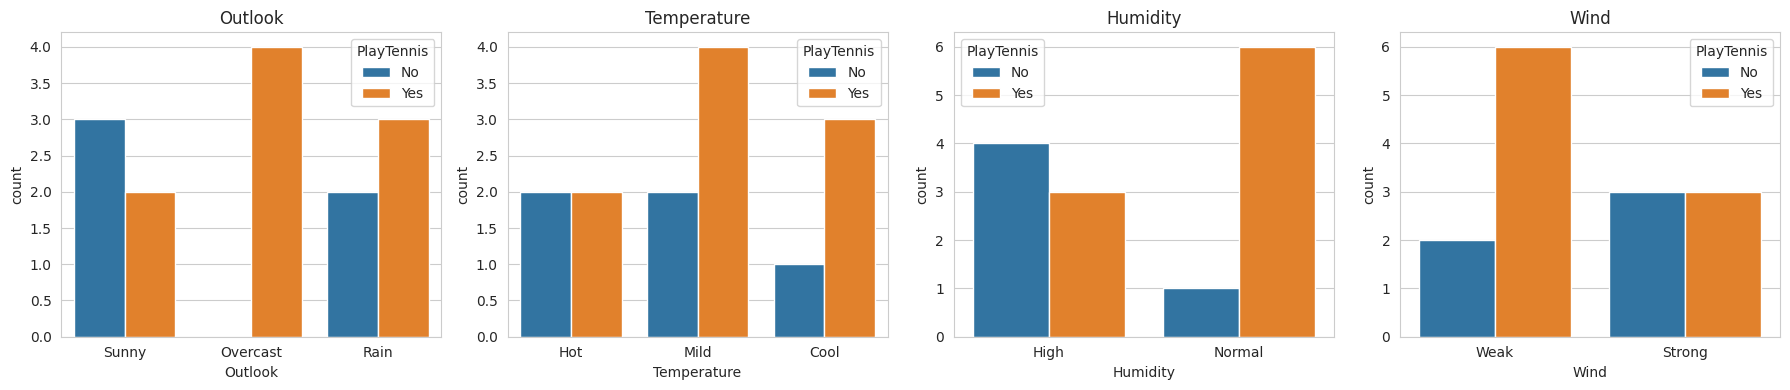

In [5]:
print(df.describe(include="all").T)
print("\nClass distribution:\n", df[target].value_counts())

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.countplot(data=df, x=col, hue=target, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

## Step 5: Model Training (ID3 from scratch)
Implement entropy, information gain and the recursive ID3 procedure.

Entropy of the whole dataset: 0.9403

Information gain of Outlook     : 0.2467
Information gain of Humidity    : 0.1518
Information gain of Wind        : 0.0481
Information gain of Temperature : 0.0292


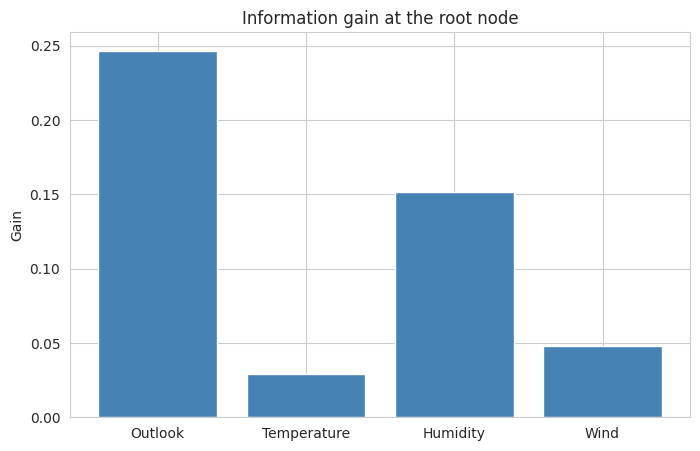

In [6]:
def entropy(series):
    p = series.value_counts(normalize=True)
    return -(p * np.log2(p)).sum()

def info_gain(data, attr, target):
    total = entropy(data[target])
    weighted = sum(len(sub) / len(data) * entropy(sub[target]) for _, sub in data.groupby(attr))
    return total - weighted

print(f"Entropy of the whole dataset: {entropy(df[target]):.4f}\n")
gains = {a: info_gain(df, a, target) for a in features}
for a, g in sorted(gains.items(), key=lambda kv: -kv[1]):
    print(f"Information gain of {a:<12}: {g:.4f}")

plt.bar(gains.keys(), gains.values(), color="steelblue")
plt.title("Information gain at the root node"); plt.ylabel("Gain"); plt.show()

In [7]:
def id3(data, target, attrs):
    labels = data[target]
    if labels.nunique() == 1:               # pure node -> leaf
        return labels.iloc[0]
    if not attrs:                           # no attributes left -> majority class
        return labels.mode()[0]
    gains = {a: info_gain(data, a, target) for a in attrs}
    best = max(gains, key=gains.get)
    node = {"attr": best, "majority": labels.mode()[0], "branches": {}}
    for value, subset in data.groupby(best):
        node["branches"][value] = id3(subset, target, [a for a in attrs if a != best])
    return node

def print_tree(node, indent=""):
    if not isinstance(node, dict):
        print(indent + "->", node)
        return
    print(indent + f"[{node['attr']}]")
    for value, child in node["branches"].items():
        print(indent + f"  = {value}:")
        print_tree(child, indent + "      ")

tree = id3(df, target, features)
print_tree(tree)

[Outlook]
  = Overcast:
      -> Yes
  = Rain:
      [Wind]
        = Strong:
            -> No
        = Weak:
            -> Yes
  = Sunny:
      [Humidity]
        = High:
            -> No
        = Normal:
            -> Yes


## Step 6: Model Evaluation
With only 14 rows a train/test split is not meaningful, so we report (a) training accuracy and (b) **Leave-One-Out cross-validation**, which is an honest estimate. We also compare against scikit-learn's decision tree using the entropy criterion.

In [8]:
def predict_one(node, sample):
    while isinstance(node, dict):
        value = sample.get(node["attr"])
        if value in node["branches"]:
            node = node["branches"][value]
        else:
            return node["majority"]          # unseen value -> fall back to majority
    return node

train_pred = [predict_one(tree, row.to_dict()) for _, row in df.iterrows()]
print("Training accuracy:", np.mean(np.array(train_pred) == df[target].values))

correct = 0
for i in range(len(df)):
    train = df.drop(df.index[i])
    t = id3(train, target, features)
    correct += predict_one(t, df.iloc[i].to_dict()) == df.iloc[i][target]
print("Leave-One-Out accuracy:", round(correct / len(df), 3))

Training accuracy: 1.0
Leave-One-Out accuracy: 0.786


scikit-learn tree training accuracy: 1.0


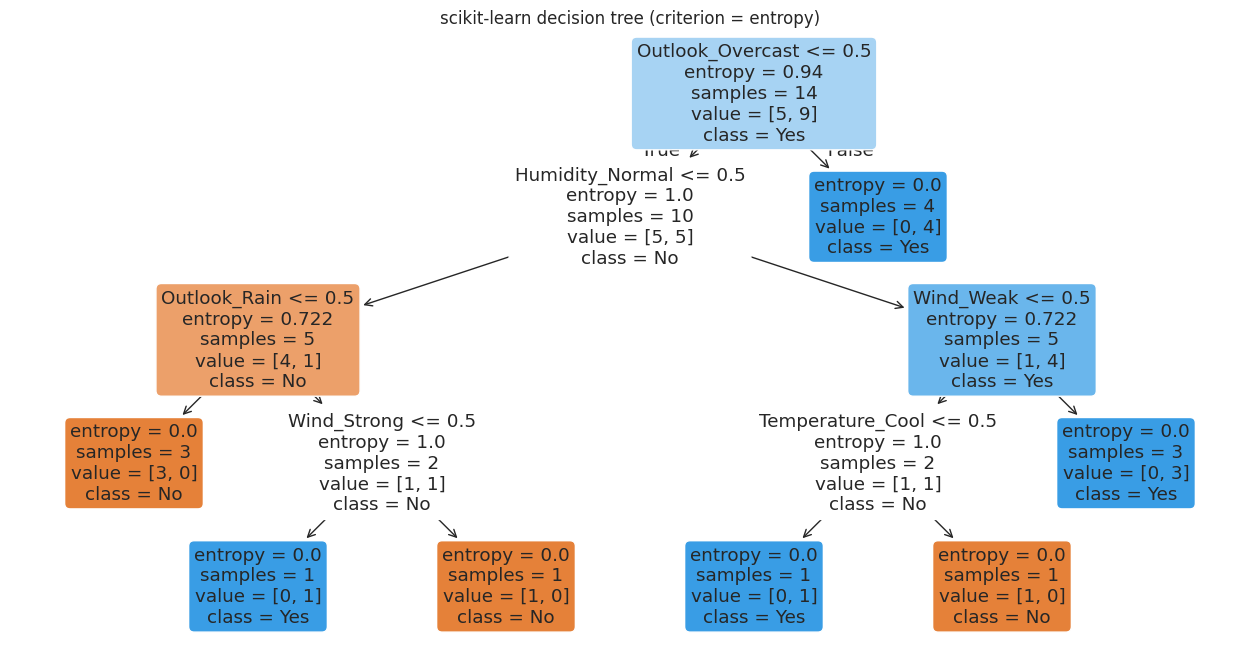

In [9]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

X_enc = pd.get_dummies(df[features])
clf = DecisionTreeClassifier(criterion="entropy", random_state=0).fit(X_enc, df[target])
print("scikit-learn tree training accuracy:", clf.score(X_enc, df[target]))

plt.figure(figsize=(16, 8))
plot_tree(clf, feature_names=X_enc.columns, class_names=clf.classes_, filled=True, rounded=True)
plt.title("scikit-learn decision tree (criterion = entropy)")
plt.show()

## Step 7: Prediction on New Data
Classify a new, unseen day using the ID3 tree we built.

In [10]:
new_day = {"Outlook": "Sunny", "Temperature": "Cool", "Humidity": "High", "Wind": "Strong"}
print("New sample:", new_day)
print("ID3 prediction -> PlayTennis =", predict_one(tree, new_day))

another = {"Outlook": "Overcast", "Temperature": "Mild", "Humidity": "High", "Wind": "Weak"}
print("\nNew sample:", another)
print("ID3 prediction -> PlayTennis =", predict_one(tree, another))

New sample: {'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'High', 'Wind': 'Strong'}
ID3 prediction -> PlayTennis = No

New sample: {'Outlook': 'Overcast', 'Temperature': 'Mild', 'Humidity': 'High', 'Wind': 'Weak'}
ID3 prediction -> PlayTennis = Yes


## Conclusion
Outlook has the highest information gain (~0.247) and becomes the root. The resulting tree classifies all 14 training days correctly and matches the structure learned by scikit-learn's entropy-based tree. ID3 can overfit small datasets, which the lower leave-one-out score reveals; pruning or more data would help.